<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="150" alt="VGI"></a>

# How do games and sets tell different match stories?

Start with the 2026 Australian Open women’s main singles draw. Expand the returned set structs, reconstruct each side’s sets and games, and compare the match winner’s game total with the opponent’s. Then describe close sets by round and vary that definition without changing the underlying scores.

The default replays **one unchanged actual public WTA response captured on 14 November 2026**. It contains the tournament’s main and qualifying singles and doubles records; SQL makes the analytical scope explicit. The real Tennis worker parses the response. These are source observations, not independently verified officiating records. [Setup, provenance and source terms](README.md).

## Set a descriptive game-margin threshold

`CLOSE_SET_MARGIN` is an integer **0–6 games**, inclusive. A set is labeled close when the absolute difference in games is at most this margin. Start at **2**; experiment **4**. This is a descriptive label, not a rule for winning sets or an estimate of point-by-point competitiveness.

`DATA_MODE` is **replay** or **live**. The event stays WTA tournament **901**, season **2026**. Live clears inherited source overrides and requests that settled event directly; it never falls back to the recording. Restart and run all after editing. Retrieval time is distinct from the UTC match timestamps.

In [1]:
DATA_MODE = "replay"  # "live" requests the same event directly.
CLOSE_SET_MARGIN = 2  # Inclusive difference in games; experiment: 4.

In [2]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

from notebook_support import audit, chart, cleanup, configure, prose, theme

server, thread, previous, run_utc, provenance = configure(DATA_MODE, CLOSE_SET_MARGIN)
source_label = "Recorded WTA • 2026-11-14 UTC" if DATA_MODE == "replay" else f"Live WTA • {run_utc[:19]} UTC"
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaylimit = 20
%sql connection

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-tennis/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-tennis/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-tennis/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-tennis/notebooks/pyproject.toml.

## Connect to the tagged worker

The literal command launches public Git tag **v0.2.0**, with pinned Python/SDK/Arrow/HTTP dependencies. First run needs internet for packages, Git and the extension. Everything local is beside this notebook; no root checkout or source environment is required. Replay serves the exact recorded JSON through the worker’s supported WTA base-URL hook.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'tennis' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-tennis@v0.2.0 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==25.0.1 --with httpx==0.28.1 vgi-tennis');
CREATE TABLE settings AS SELECT {{ CLOSE_SET_MARGIN }}::INTEGER AS close_margin;

Running query in 'DuckDBPyConnection'

1 rows affected.

,Count


In [4]:
prose(
    f"**{source_label}.** WTA Australian Open, tournament **901 / season 2026**. "
    f"Recorded response captured **{provenance['captured_utc']}**. "
    + (
        "The recording drives this run."
        if DATA_MODE == "replay"
        else "That is the archive time; this run uses a fresh response."
    )
    + f" Close-set definition: absolute game difference **≤ {CLOSE_SET_MARGIN}**."
)

**Recorded WTA • 2026-11-14 UTC.** WTA Australian Open, tournament **901 / season 2026**. Recorded response captured **2026-11-14T10:24:03.299161+00:00**. The recording drives this run. Close-set definition: absolute game difference **≤ 2**.

## Retrieve once and account for the scope

Materialize the whole tournament before filtering, so charting never repeats an API call. Report records by draw, qualifying flag and status. Only main-draw singles with completed status enter the candidate cohort. Retirements, walkovers, doubles and qualifying matches remain outside this question, even when they have some score information. WTA player/match IDs are used only within this source and event.

In [5]:
%%sql
CREATE TABLE tournament AS SELECT * FROM tennis.main.tournament_matches('WTA',901,2026);
SELECT draw_type,qualifying,status,count(*) AS matches,
    min(scheduled_at) AT TIME ZONE 'UTC' AS first_scheduled_utc,
    max(scheduled_at) AT TIME ZONE 'UTC' AS last_scheduled_utc
FROM tournament GROUP BY ALL ORDER BY draw_type,qualifying,status;

Running query in 'DuckDBPyConnection'

302 rows affected.

,draw_type,qualifying,status,matches,first_scheduled_utc,last_scheduled_utc
0,doubles,False,completed,63,2026-01-20 00:00:00,2026-01-31 01:00:00
1,singles,False,completed,127,2026-01-18 00:00:00,2026-01-31 08:40:00
2,singles,True,completed,112,2026-01-11 23:00:00,2026-01-15 05:35:00


## Reconstruct set outcomes before summing games

A valid completed singles set here ends **6–0 through 6–4, 7–5 or 7–6**, in either direction. Keep only matches with two or three such sets and a known winner side. Missing scores, partial sets and match-tiebreak encodings are excluded explicitly. This prevents a doubles match tiebreak stored as 1–0 from being counted as ordinary games.

Game totals exclude tiebreak **points**: 7–6 is thirteen games regardless of its point score. Reconstructed sets won must agree with the worker’s reported set counts and with the declared match winner. We derive who won from set comparisons, never from the larger aggregate game total.

In [6]:
%%sql
CREATE TABLE candidates AS SELECT * FROM tournament
WHERE source='wta' AND season=2026 AND tournament_id=901
    AND draw_type='singles' AND NOT qualifying AND status='completed';
CREATE TABLE set_rows AS
SELECT c.match_id,c.round,c.winner_side,s.set_number,s.side1_games,s.side2_games,
    abs(s.side1_games-s.side2_games) AS game_margin,
    coalesce((greatest(s.side1_games,s.side2_games)=6 AND least(s.side1_games,s.side2_games) BETWEEN 0 AND 4)
      OR (greatest(s.side1_games,s.side2_games)=7 AND least(s.side1_games,s.side2_games) IN (5,6)),false)
      AND s.side1_games IS NOT NULL AND s.side2_games IS NOT NULL AS standard_set
FROM candidates c,UNNEST(c.sets) AS u(s);
CREATE TABLE reconstruction AS
SELECT match_id,count(*) AS sets_played,count(*) FILTER(WHERE standard_set) AS valid_sets,
    count(*) FILTER(WHERE side1_games>side2_games) AS reconstructed_side1_sets,
    count(*) FILTER(WHERE side2_games>side1_games) AS reconstructed_side2_sets,
    sum(side1_games) AS side1_games,sum(side2_games) AS side2_games
FROM set_rows GROUP BY match_id;
CREATE TABLE eligibility AS
SELECT c.*,r.* EXCLUDE(match_id),
    CASE WHEN c.winner_side IS NULL OR c.winner_side NOT IN (1,2) THEN 'unknown winner'
         WHEN r.sets_played IS NULL THEN 'missing set rows'
         WHEN r.sets_played NOT IN (2,3) OR r.valid_sets<>r.sets_played THEN 'unsupported set scores'
         ELSE 'eligible' END AS assessment
FROM candidates c LEFT JOIN reconstruction r USING(match_id);
CREATE TABLE eligible AS SELECT *,
    CASE winner_side WHEN 1 THEN side1_games ELSE side2_games END AS winner_games,
    CASE winner_side WHEN 1 THEN side2_games ELSE side1_games END AS opponent_games
FROM eligibility WHERE assessment='eligible';
SELECT assessment,count(*) AS matches FROM eligibility GROUP BY assessment ORDER BY assessment;

Running query in 'DuckDBPyConnection'

127 rows affected.

290 rows affected.

126 rows affected.

127 rows affected.

124 rows affected.

,assessment,matches
0,eligible,124
1,missing set rows,1
2,unsupported set scores,2


In [7]:
%%sql match_totals <<
SELECT match_id,round,winner_name,loser_name,score,sets_played,winner_games,opponent_games
FROM eligible ORDER BY match_id;

Running query in 'DuckDBPyConnection'

In [8]:
if match_totals.empty:
    raise ValueError("No eligible completed main-draw singles matches with supported set scores")
minority = match_totals.loc[match_totals.winner_games < match_totals.opponent_games]
display(minority[["round", "winner_name", "loser_name", "score", "winner_games", "opponent_games"]])
prose(
    f"Among **{len(match_totals)} eligible matches**, "
    f"**{len(minority)} winners** won fewer total games than their opponents. "
    "The table lists those cases; an empty table means none in the selected response. "
    "Winning more sets determines this result. Total games measure a different aspect of the scoreline."
)

,round,winner_name,loser_name,score,winner_games,opponent_games
59,Round 2,Nikola Bartunkova,Belinda Bencic,6-3 0-6 6-4,12.0,13.0
65,Round 1,Laura Siegemund,Liudmila Samsonova,0-6 7-5 6-4,13.0,15.0
111,Round 1,Nikola Bartunkova,Daria Kasatkina,7-6(7) 0-6 6-3,13.0,15.0
122,Round 1,Zhuoxuan Bai,Anastasia Pavlyuchenkova,6-4 2-6 7-6(10),15.0,16.0


Among **124 eligible matches**, **4 winners** won fewer total games than their opponents. The table lists those cases; an empty table means none in the selected response. Winning more sets determines this result. Total games measure a different aspect of the scoreline.

In [9]:
%%sql score_pairs <<
SELECT winner_games,opponent_games,sets_played,count(*) AS matches
FROM eligible GROUP BY ALL ORDER BY sets_played,winner_games,opponent_games;

Running query in 'DuckDBPyConnection'

findfont: Failed to find font weight semibold for Arial, now using 700.


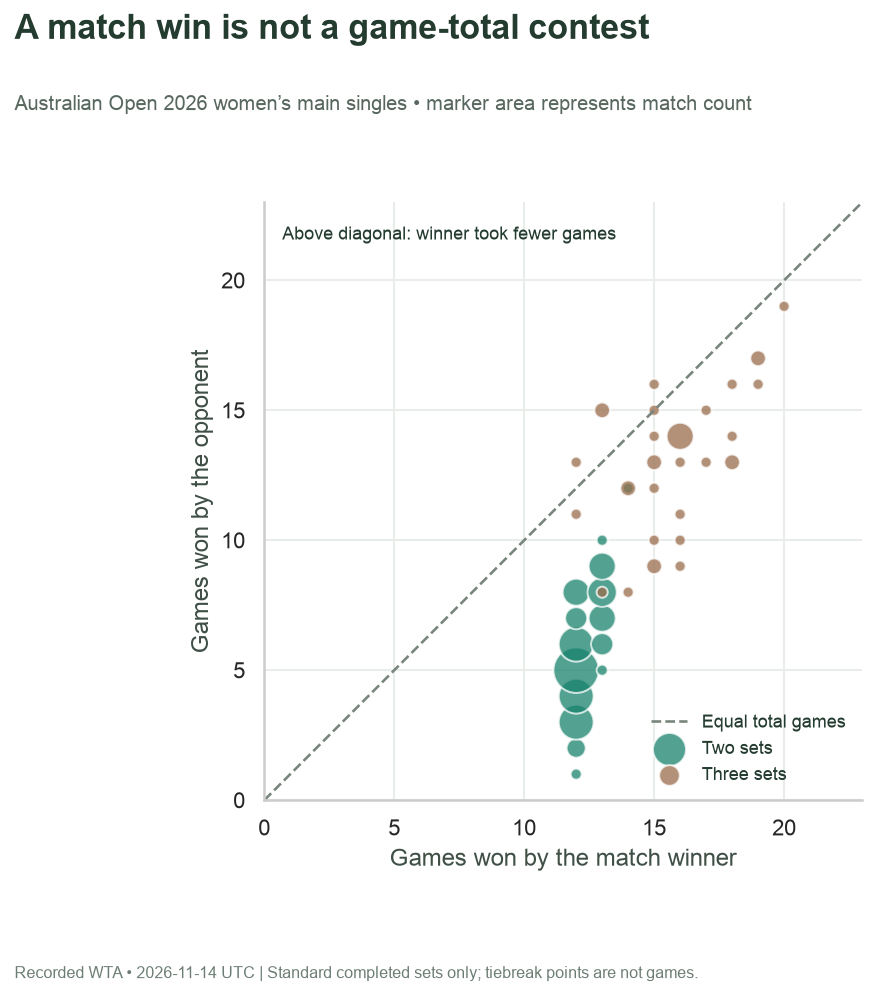

In [10]:
fig, ax = plt.subplots(figsize=(8.8, 7))
limit = max(score_pairs.winner_games.max(), score_pairs.opponent_games.max()) + 3
ax.plot([0, limit], [0, limit], color="#77857C", linestyle="--", linewidth=1.3, label="Equal total games")
for sets, color, label in [(2, "#19836D", "Two sets"), (3, "#9A6D4C", "Three sets")]:
    part = score_pairs.loc[score_pairs.sets_played == sets]
    ax.scatter(
        part.winner_games,
        part.opponent_games,
        s=part.matches * 30,
        color=color,
        alpha=0.75,
        edgecolor="white",
        label=label,
    )
ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Games won by the match winner")
ax.set_ylabel("Games won by the opponent")
ax.legend(loc="lower right", fontsize=9)
ax.text(0.03, 0.96, "Above diagonal: winner took fewer games", transform=ax.transAxes, va="top", fontsize=9)
chart(
    fig,
    "A match win is not a game-total contest",
    "Australian Open 2026 women’s main singles • marker area represents match count",
    source_label + " | Standard completed sets only; tiebreak points are not games.",
)

## Describe close sets by round

Apply the inclusive game-margin label to the eligible set rows, then retain both close and wider counts. Each bar’s denominator is the number of observed eligible sets in that round. Later rounds have much smaller samples; these percentages do not estimate how a different draw would play out. No point-by-point data or uncertainty model is available here.

In [11]:
%%sql round_counts <<
SELECT s.round,count(*) AS sets,
    count(*) FILTER(WHERE s.game_margin<=(SELECT close_margin FROM settings)) AS close_sets,
    count(*) FILTER(WHERE s.game_margin>(SELECT close_margin FROM settings)) AS wider_sets,
    100.0*count(*) FILTER(WHERE s.game_margin<=(SELECT close_margin FROM settings))/count(*) AS close_percent
FROM set_rows s JOIN eligible e USING(match_id)
GROUP BY s.round ORDER BY CASE s.round WHEN 'Round 1' THEN 1 WHEN 'Round 2' THEN 2
    WHEN 'Round 3' THEN 3 WHEN 'Round 4' THEN 4 WHEN 'Quarterfinal' THEN 5
    WHEN 'Semifinal' THEN 6 WHEN 'Final' THEN 7 ELSE 99 END;

Running query in 'DuckDBPyConnection'

,round,sets,close_sets,wider_sets,close_percent
0,Round 1,146,56,90,38.356164
1,Round 2,73,30,43,41.095890
2,Round 3,34,12,22,35.294118
3,Round 4,17,5,12,29.411765
4,Quarterfinal,8,2,6,25.000000
5,Semifinal,4,1,3,25.000000
6,Final,3,3,0,100.000000


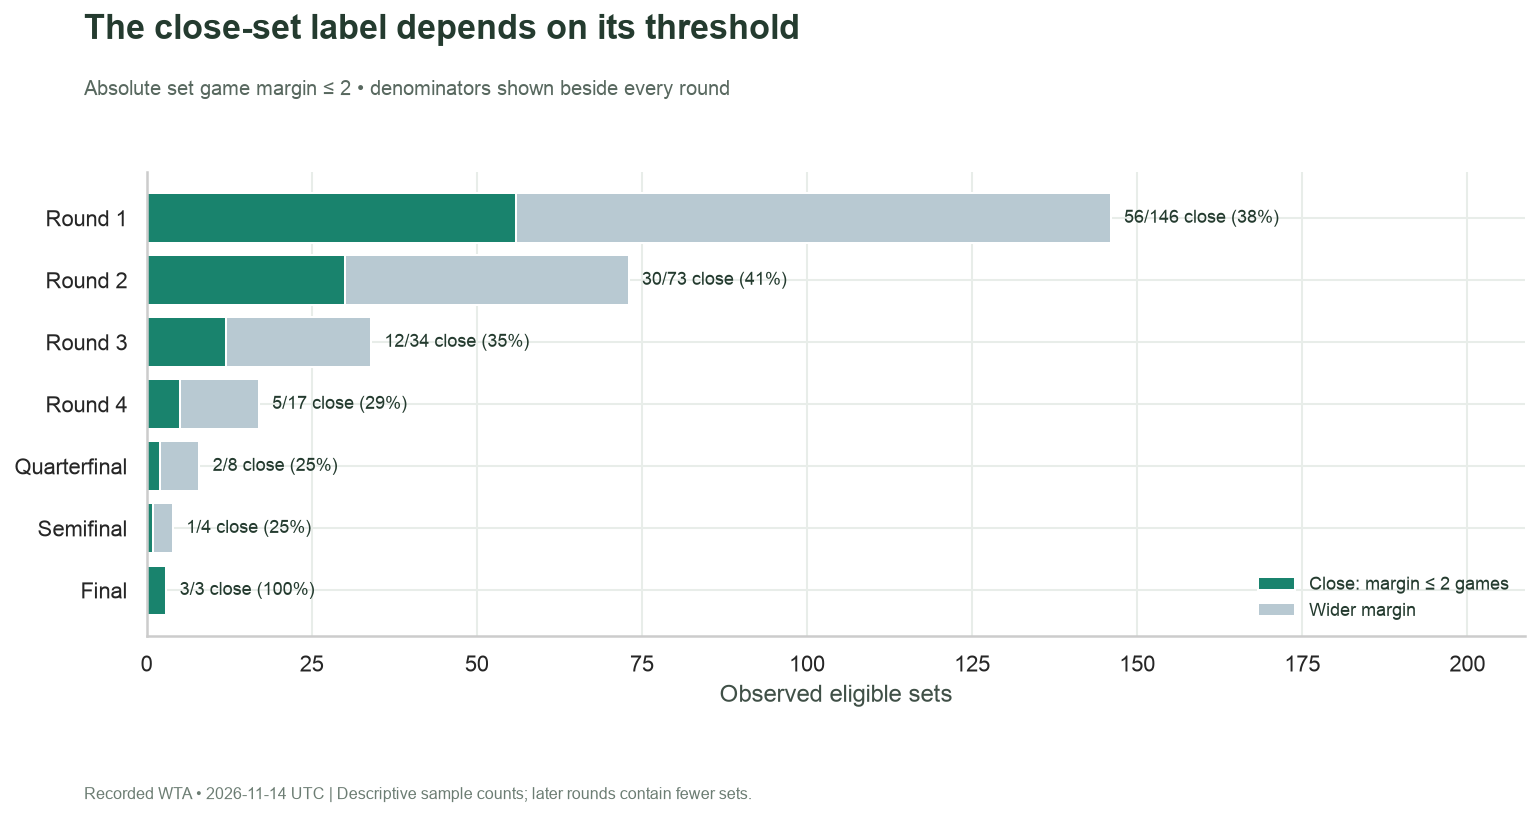

In [12]:
display(round_counts)
fig, ax = plt.subplots(figsize=(11, 5.7))
y = np.arange(len(round_counts))
ax.barh(y, round_counts.close_sets, color="#19836D", label=f"Close: margin ≤ {CLOSE_SET_MARGIN} games")
ax.barh(y, round_counts.wider_sets, left=round_counts.close_sets, color="#B8C9D2", label="Wider margin")
for i, row in enumerate(round_counts.itertuples()):
    ax.text(
        row.sets + 2,
        i,
        f"{row.close_sets}/{row.sets} close ({row.close_percent:.0f}%)",
        va="center",
        fontsize=9,
    )
ax.set_yticks(y, round_counts["round"])
ax.invert_yaxis()
ax.set_xlim(0, round_counts.sets.max() * 1.43)
ax.set_xlabel("Observed eligible sets")
ax.legend(loc="lower right", fontsize=9)
chart(
    fig,
    "The close-set label depends on its threshold",
    f"Absolute set game margin ≤ {CLOSE_SET_MARGIN} • denominators shown beside every round",
    source_label + " | Descriptive sample counts; later rounds contain fewer sets.",
)

In [13]:
total_sets = int(round_counts.sets.sum())
close_sets = int(round_counts.close_sets.sum())
prose(
    f"The selected **{total_sets} sets** include "
    f"**{close_sets} close sets ({100 * close_sets / total_sets:.1f}%)** "
    f"under a **≤{CLOSE_SET_MARGIN}-game** margin. "
    "The threshold changes this classification, while raw scores, winners and the first chart remain fixed. "
    + audit(server)
)

The selected **285 sets** include **109 close sets (38.2%)** under a **≤2-game** margin. The threshold changes this classification, while raw scores, winners and the first chart remain fixed. Replay audit: exactly one WTA tournament request; no additional provider requests.

## Verify the score reconstruction

These checks validate keys, source scope, complete set coverage and agreement with the worker’s declared winner. They do not require a particular champion, minority-game winner count or close-set percentage. The main analytical scope excludes unsupported scoring rather than silently converting it to zero.

In [14]:
%%sql checks <<
SELECT 'source match keys unique' AS check_name,(SELECT count(*)=count(DISTINCT match_id) FROM tournament) AS passed
UNION ALL SELECT 'required cohort present',(SELECT count(*) FROM eligible)>0
UNION ALL SELECT 'eligible set rows unique',NOT EXISTS(SELECT s.match_id,s.set_number FROM set_rows s JOIN eligible e USING(match_id) GROUP BY ALL HAVING count(*)<>1)
UNION ALL SELECT 'all scored sets retained',NOT EXISTS(SELECT 1 FROM eligible WHERE sets_played<>len(sets))
UNION ALL SELECT 'supported terminal sets',NOT EXISTS(SELECT 1 FROM set_rows s JOIN eligible e USING(match_id) WHERE NOT standard_set)
UNION ALL SELECT 'side1 set count agrees',NOT EXISTS(SELECT 1 FROM eligible WHERE reconstructed_side1_sets IS DISTINCT FROM side1_sets_won)
UNION ALL SELECT 'side2 set count agrees',NOT EXISTS(SELECT 1 FROM eligible WHERE reconstructed_side2_sets IS DISTINCT FROM side2_sets_won)
UNION ALL SELECT 'winning side won two sets',NOT EXISTS(SELECT 1 FROM eligible WHERE CASE winner_side WHEN 1 THEN reconstructed_side1_sets ELSE reconstructed_side2_sets END<>2)
UNION ALL SELECT 'other side won at most one set',NOT EXISTS(SELECT 1 FROM eligible WHERE CASE winner_side WHEN 1 THEN reconstructed_side2_sets ELSE reconstructed_side1_sets END NOT IN(0,1))
UNION ALL SELECT 'game totals conserve both sides',NOT EXISTS(SELECT 1 FROM eligible WHERE winner_games+opponent_games<>side1_games+side2_games)
UNION ALL SELECT 'set expansion conserves eligible sets',(SELECT count(*) FROM set_rows s JOIN eligible e USING(match_id))=(SELECT sum(sets_played) FROM eligible)
UNION ALL SELECT 'scope remains WTA main singles',NOT EXISTS(SELECT 1 FROM eligible WHERE source<>'wta' OR draw_type<>'singles' OR qualifying OR status<>'completed');

Running query in 'DuckDBPyConnection'

In [15]:
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
prose(f"**All {len(checks)} SQL checks passed.** " + audit(server))

,check_name,passed
0,source match keys unique,True
1,required cohort present,True
2,eligible set rows unique,True
3,all scored sets retained,True
4,supported terminal sets,True
5,side1 set count agrees,True
6,side2 set count agrees,True
7,winning side won two sets,True
8,other side won at most one set,True
9,game totals conserve both sides,True


**All 12 SQL checks passed.** Replay audit: exactly one WTA tournament request; no additional provider requests.

## Experiment: widen the close-set definition

Change only **CLOSE_SET_MARGIN from 2 to 4** in replay mode and rerun in a separate output directory. Predict that close-set counts cannot decrease, while each round’s total sets, reconstructed winners and the games scatter stay identical. Compare the second chart’s counts and percentages; explain why the denominator must remain fixed.

This is a sensitivity test for a descriptive label. It does not change the rules, reveal point-level pressure, or establish that one round was harder. A later live correction is a separate source change. Restore **2** to return to the saved example; [the README](README.md) gives experiment and live commands.

In [16]:
connection.close()
cleanup(server, thread, previous)

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>